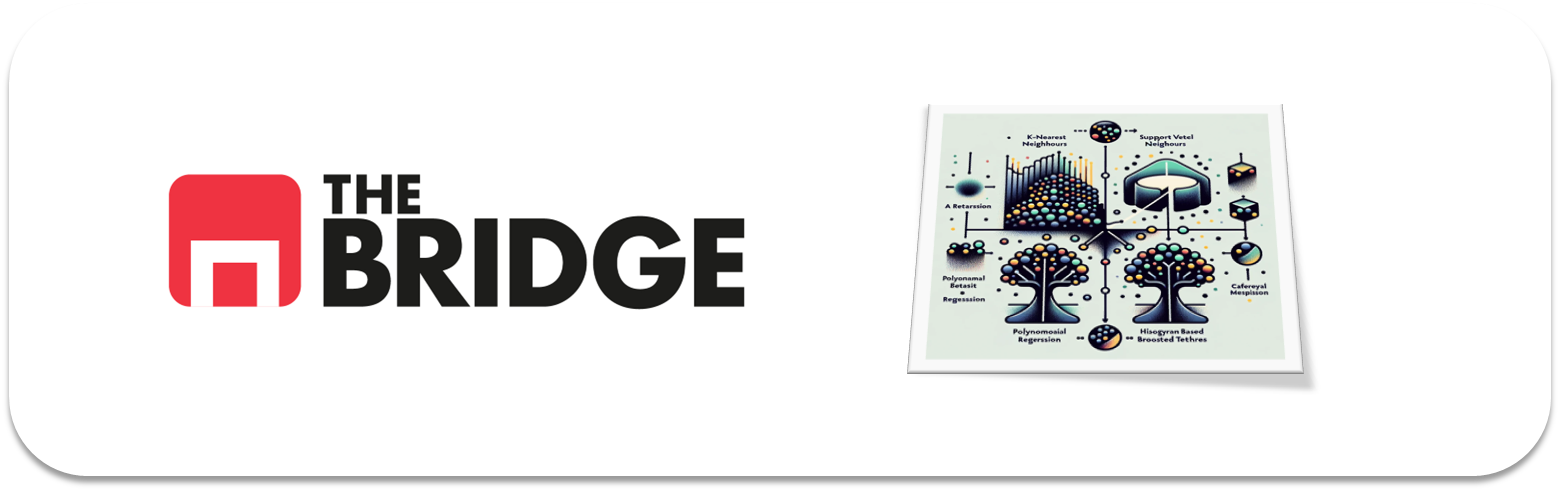

## **Repaso Aprendizaje Supervisado**

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import bootcampviztools as bt
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns

from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, make_scorer, precision_score, ConfusionMatrixDisplay,mean_absolute_percentage_error
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier, XGBRegressor

In [2]:

def plot_predictions_vs_actual(y_real, y_pred):
    """
    Función para graficar los valores reales vs. los valores predichos en una regresión.

    Args:
    y_real (array-like): Valores reales de la variable objetivo.
    y_pred (array-like): Valores predichos de la variable objetivo.
    """
    plt.figure(figsize=(8, 6))
    plt.scatter(y_pred, y_real, alpha=0.5)
    plt.xlabel("Valores Predichos")
    plt.ylabel("Valores Reales")

    # Línea y=x
    max_value = max(max(y_real), max(y_pred))
    min_value = min(min(y_real), min(y_pred))
    plt.plot([min_value, max_value], [min_value, max_value], 'r')

    plt.title("Comparación de Valores Reales vs. Predichos")
    plt.show()

### #1 Explicación del dataset y carga de datos

Vamos a trabajar con el dataset "Wine Quality", que es un dataset en el que se recogen diversas características fisicoquímicas de las variades tinta y blanca del "Vinho verde" portugués. Las variables del dataset se describen a continuación


1. **Acidez fija**: La mayoría de los ácidos involucrados con el vino son fijos o no volátiles (no se evaporan fácilmente).
2. **Acidez volátil**: La cantidad de ácido acético en el vino, que en niveles demasiado altos puede llevar a un sabor desagradable a vinagre.
3. **Ácido cítrico**: Encontrado en pequeñas cantidades, el ácido cítrico puede añadir 'frescura' y sabor a los vinos.
4. **Azúcar residual**: Es la cantidad de azúcar restante después de que se detiene la fermentación, es raro encontrar vinos con menos de 1 gramo/litro y vinos con más de 45 gramos/litro se consideran dulces.
5. **Cloruros**: La cantidad de sal en el vino.
6. **Dióxido de azufre libre**: La porción libre de SO2 existe en equilibrio entre el SO2 molecular (como un gas disuelto) y el ion bisulfito; previene el crecimiento microbiano y la oxidación del vino.
7. **Dióxido de azufre total**: Es la cantidad de formas libres y ligadas de S02; en bajas concentraciones, el SO2 es en su mayoría indetectable en el vino, pero en concentraciones libres de más de 50 ppm, el SO2 se hace evidente en la nariz y el sabor del vino.
8. **Densidad**: La densidad del vino es cercana a la del agua dependiendo del porcentaje de alcohol y contenido de azúcar.
9. **pH**: Describe qué tan ácido o básico es un vino en una escala de 0 (muy ácido) a 14 (muy básico); la mayoría de los vinos están entre 3-4 en la escala de pH.
10. **Sulfatos**: Un aditivo del vino que puede contribuir a los niveles de dióxido de azufre (SO2), que actúa como un antimicrobiano y antioxidante.
11. **Alcohol**: El porcentaje de contenido de alcohol del vino.
12. **Calidad**: Una variable de salida (basada en datos sensoriales, puntuación entre 0 y 10).
13. **Class**: Si es blanco o tinto.



Carga el dataset "wines_dataset.csv", muestra sus primeras filas, su información general y define dos variables target una para clasificación que permita predecir la calidad del vino según el resto de propiedas y otra variable target para regresión que permita predecir el grado alcohólico del vino a partir del resto de propiedades. 

El **objetivo de negocio en el primer problema** será anticipar la posible clasificación de sus vinos por los catadores profesionales y a partir de ahí poder planificar la producción, distribución y precio que poner a cada vino. En este sentido, el "cliente" nos dice que le gustaría poder clasificar correctamente lo mejor posible en media  (que interpretamos como el mejor recall medio posible).

El **objetivo de negocio en el segundo problema** (bastante artificial) es poder hacer simulaciones de posibles vinos futuros para saber cómo conseguir variedades más o menos alcohólicas para atender mercados diferentes. En este sentido, les interesa equivocarse lo menos posible porcentualmente sobre el grado alcohólico real.

Muestra la distribución de ambos targets y haz un pequeño assessment previo de cada problema. NOTA: El dataset está limpio y sin valores faltantes.

In [3]:
df = pd.read_csv("./data/wines_dataset.csv", sep = "|")

In [4]:
df.head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,class
0,8.5,0.210,0.26,9.25,0.034,73.0,142.0,0.99450,3.05,0.37,11.4,6,white
1,8.3,0.160,0.37,7.90,0.025,38.0,107.0,0.99306,2.93,0.37,11.9,6,white
2,6.8,0.180,0.38,1.40,0.038,35.0,111.0,0.99180,3.32,0.59,11.2,7,white
3,6.1,0.260,0.25,2.90,0.047,289.0,440.0,0.99314,3.44,0.64,10.5,3,white
4,7.5,0.630,0.27,2.00,0.083,17.0,91.0,0.99616,3.26,0.58,9.8,6,red
5,5.7,0.265,0.28,6.90,0.036,46.0,150.0,0.99299,3.36,0.44,10.8,7,white
6,6.6,0.210,0.31,11.40,0.039,46.0,165.0,0.99795,3.41,0.44,9.8,7,white
7,6.7,0.310,0.30,2.10,0.038,18.0,130.0,0.99280,3.36,0.63,10.6,6,white
8,8.9,0.750,0.14,2.50,0.086,9.0,30.0,0.99824,3.34,0.64,10.5,5,red
9,7.5,0.420,0.20,1.40,0.060,15.0,168.0,0.99440,3.06,0.40,9.4,6,white


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  class                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 688.6 KB


In [6]:
target_clf = "quality"
target_reg = "alcohol"

*Para el caso del target de clasificación:*

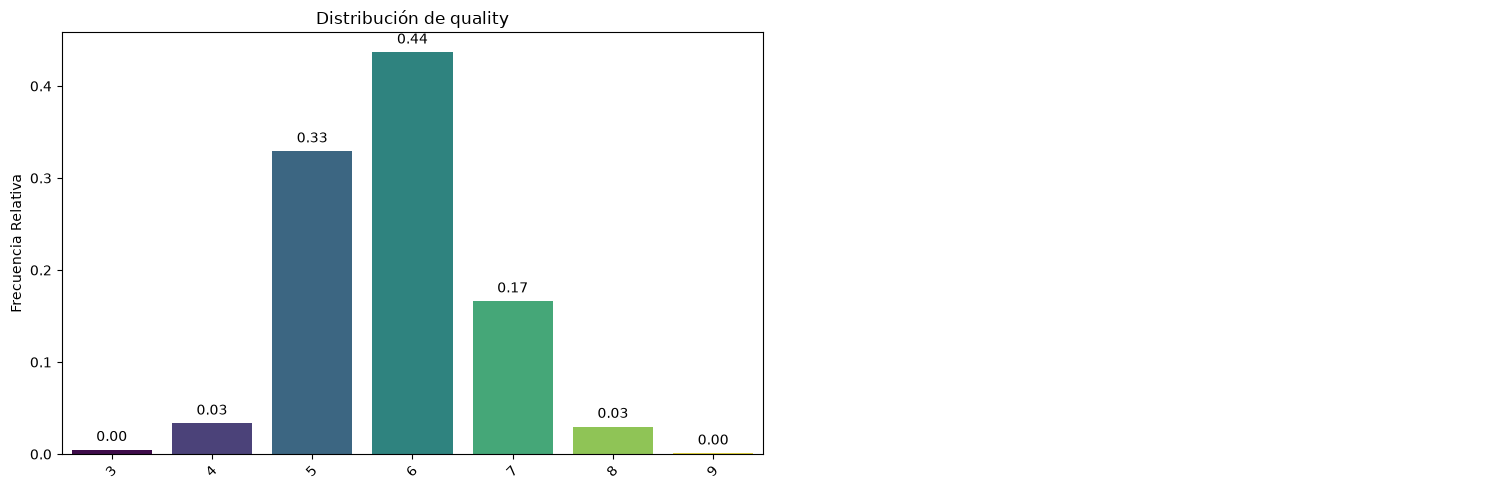

In [7]:
bt.pinta_distribucion_categoricas(df, [target_clf], mostrar_valores = True, relativa = True)

*Se trata de un problema multiclase fuertemente desequilibrado, algo tendremos que hacer con esa situación*

*En el caso del alcohol*

<Axes: xlabel='alcohol', ylabel='Count'>

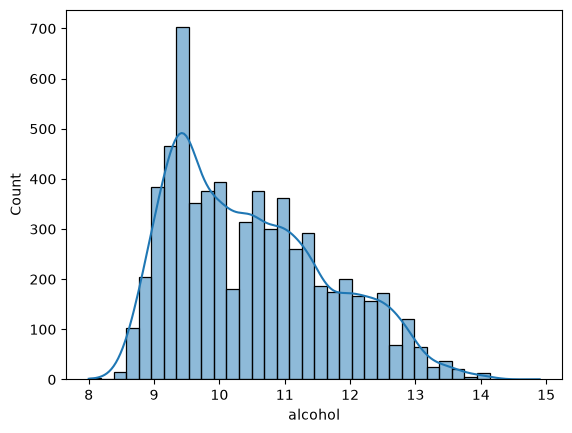

In [8]:
sns.histplot(df[target_reg], kde = True)

*Tiene una distribución que no es exactmente normal pero no tiene mala pinta incluso para una regresión lineal*

### #2 Modelado para clasificación

Crea un modelo que permita clasificar lo mejor posible los vinos en función de su calidad, o dicho de otro modo que prediga de la mejor manera posible la calidad de un vino a partir de sus propiedades químicas. ***Considéralo un problema de clasificación***, donde los valores de calidad son las clases para predecir. Puedes utilizar los modelos que creas conveniente, al menos tres, y utiliza un KNN como modelo baseline, prueba al menos con 2 valores de K. Intenta mejorar el "recall medio" con las técnicas que creas conveniente. Compara los modelos utilizando validación cruzada con o sin optimización previa de hiperparámetros (por tiempo nosotros sólo lo haremos con validación cruzada). El modelo elegido sí tiene que tener un ejemplo de optimización de parámetros.

Evalúa el modelo, analiza los errores y propón algún mecanismo de mejora aunque sea sólo un esbozo.

Siguiendo el esquema:

1. Entendimiento del problema (selección de la métrica más adecuada)  
2. Obtención de datos y primer contacto  
3. Train y Test  <- PARTIMOS DE AQUI
4. MiniEDA: Análisis del target, análisis bivariante, entendimiento de las features, selección de las mismas (si es necesario)
    Categoricas -> 0-1 -> MinMax (a,b), con a < b
    Categoricas -> 0 a 10 y numericas -> StandardScaler -> 2 juegos 
5. Preparación del dataset de Train: Conversión de categóricas, tratamiento de numéricas  
6. Selección e instanciación de modelos. Baseline.
7. Comparación de modelos (lo haremos por comparación con validación, puedes hacerlo por comparación de modelos de hiperparámetros optimizados, si así lo prefieres)  TIEMPO es la clave -> 1) Tuneo/Ajusto los hiperparámetros; 2) validación cruzada (set de validación)
8. Selección de modelo: Optimización de hiperparámetros (ten en cuenta la nota de 7) (hiperparametro -> class_weight) 
9. Equilibrado del train set  (Oversampling SMOTE, Undersampling....)
10. Evaluación contra test.  
11. Análisis de errores, posibles acciones futuras.  
12. EXTRA: Persistencia del modelo en disco.  

In [9]:
# Nos vale para los dos problemas:
train_set, test_set = train_test_split(df, test_size = 0.2, random_state = 42)


*Para el miniEDA vamos a hacer los dos uno detrás de otro y generaremos las listas de features separadas si es necesario (hay que quitar los targets correspondientes)*

*Partimos de que son todas numéricas excepto class (y quality en el caso del problema de regresión)*

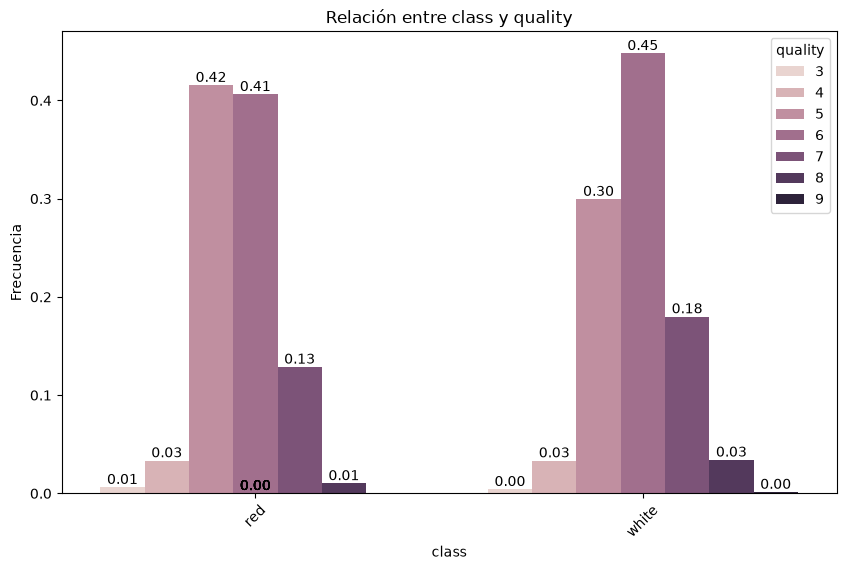

In [10]:
# MiniEDA: Clasificación

# Categóricas 

bt.plot_categorical_relationship_fin(train_set, "class", target_clf, show_values= True, relative_freq= True)


*Hay ligera diferencia (entre 5,6 y 7) que me invita a quedármela aunque no espero un gran impacto*


In [11]:
features_cat_clf = ["class"]

In [12]:
# Analizamos las numéricas 

features_num_clf = [col for col in train_set.columns if col != "class" and col != target_clf] # Me quedo con todas que no son categóricas, ni el target
print(len(features_num_clf)) # Veo cuántas son para saber qué utilizar si pairplot o las funciones de bt (bootviztools)

11


*Utilizando bootviztools*

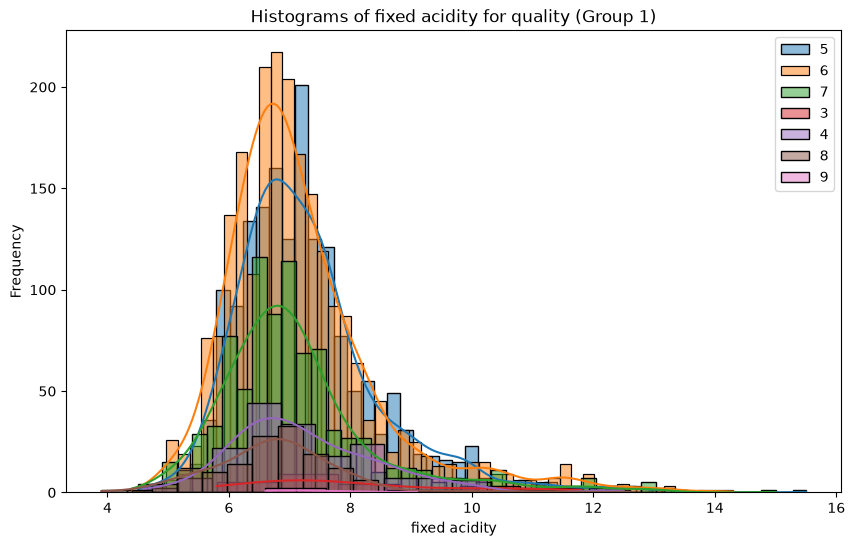

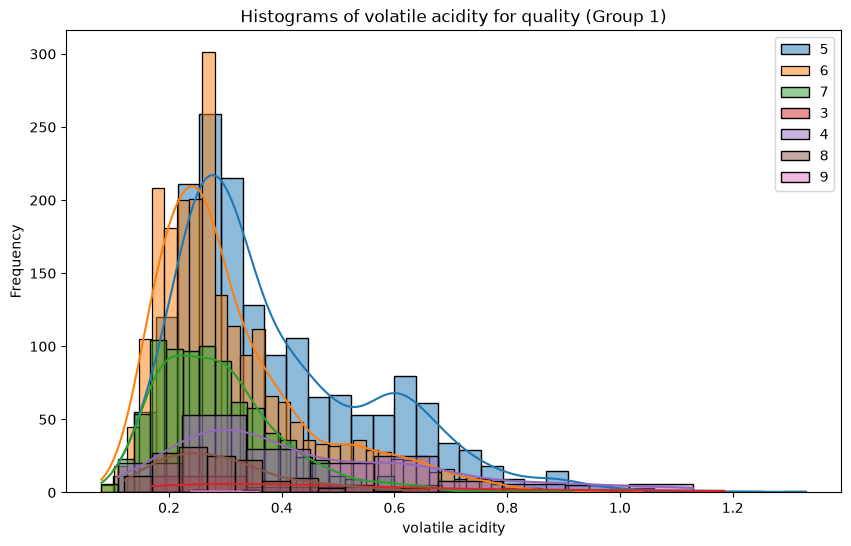

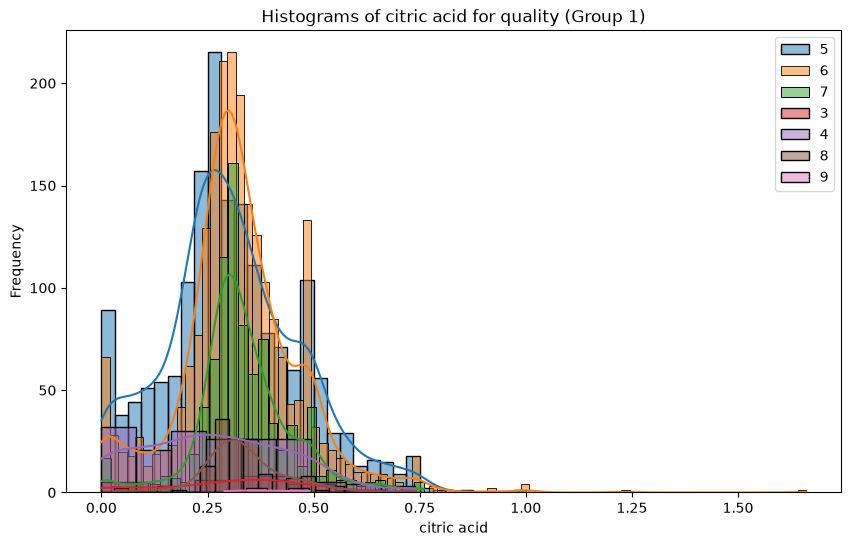

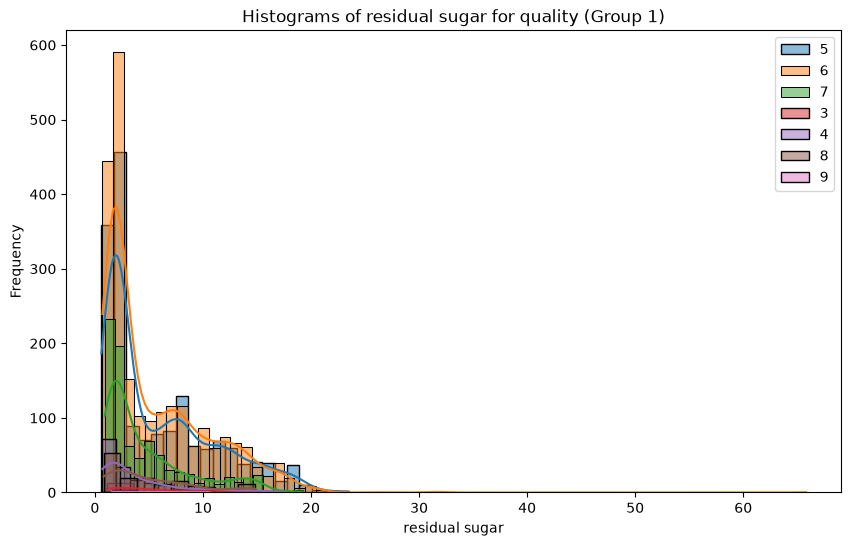

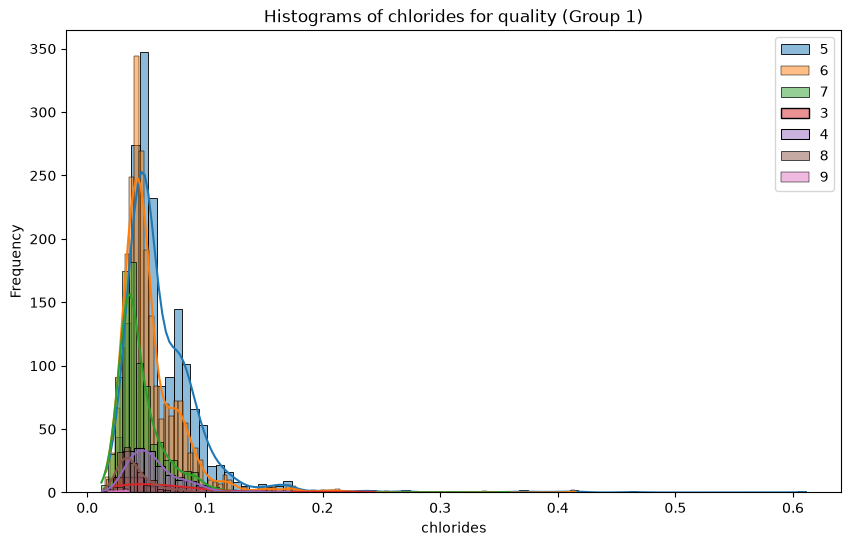

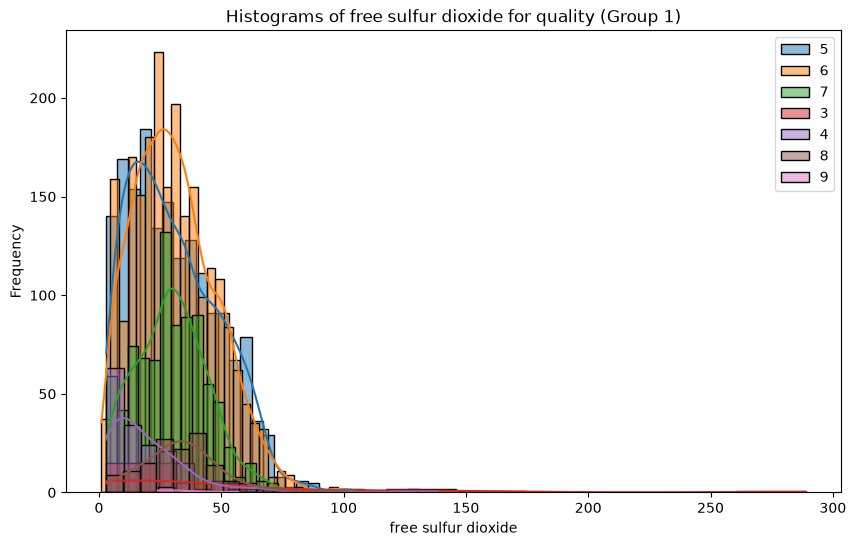

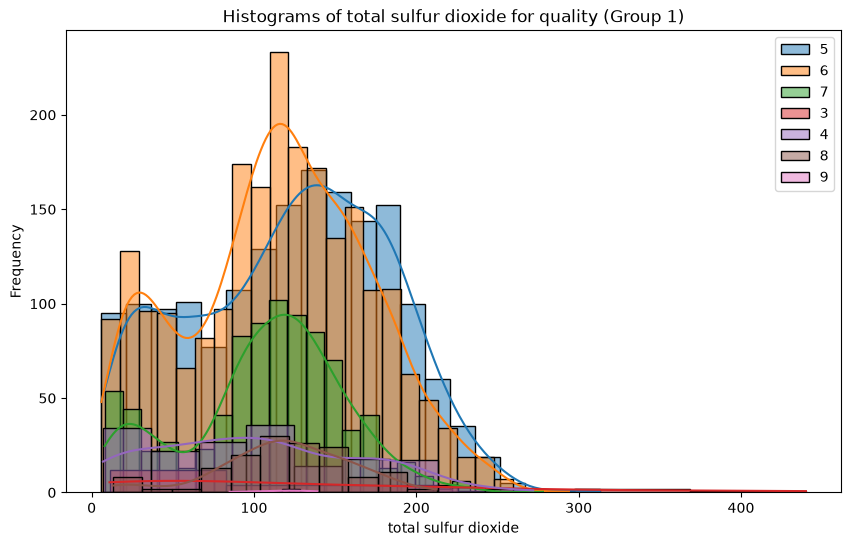

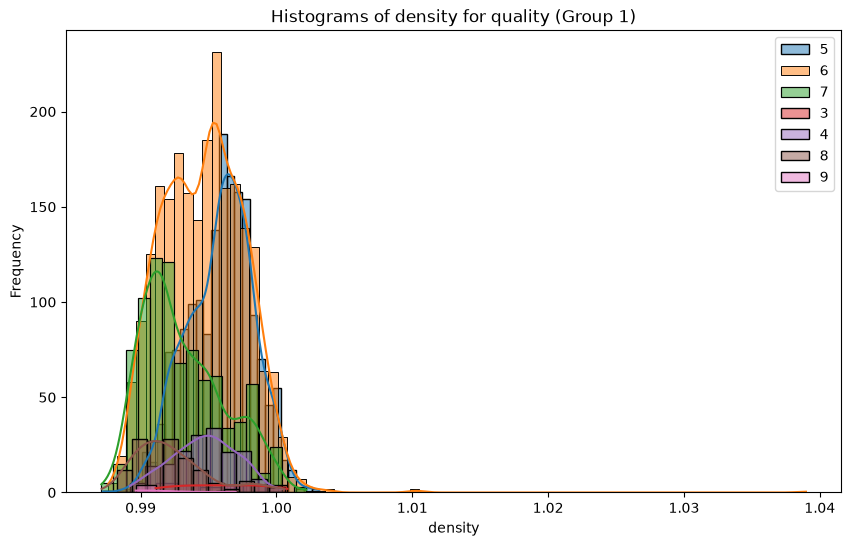

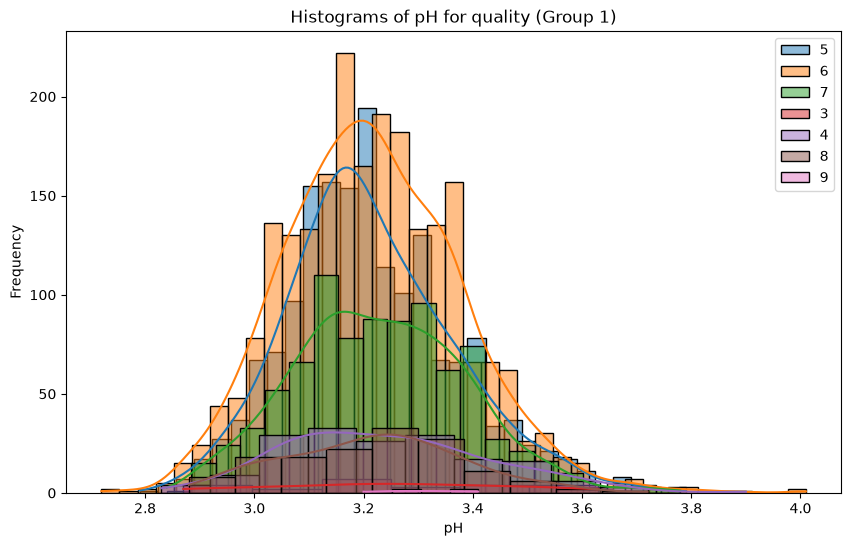

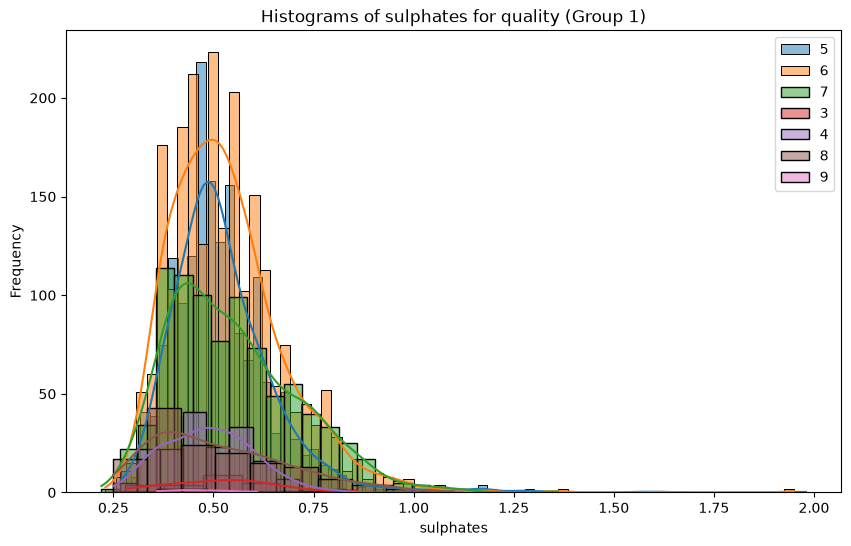

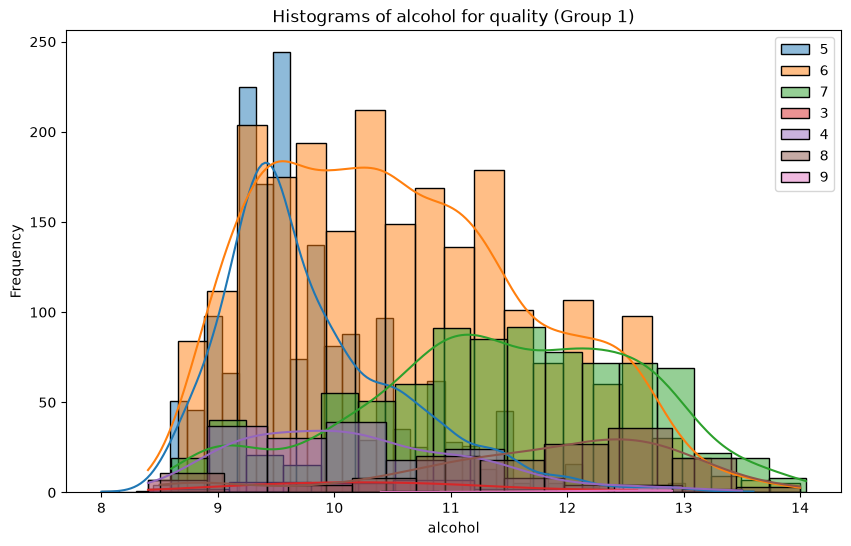

In [13]:
for col in features_num_clf:
    bt.plot_grouped_histograms(train_set, cat_col= target_clf, num_col= col, group_size= train_set[target_clf].nunique())

*Analizando una a una:*  
***fixed_acidity***: *En general bastante superposición de todas las distribuciones. Secundaria*  
***volatile_acidity***: *Tiene un desplazamiento entre 5 y 6 y varios ligeros desplazamientos del resto. Primaria aunque sin expectativas*   
***citric_acid****: Desplazamiento, ligero pero existente entre casi todas las curvas. Primaria sin expectativas*  
***residual_sugar****: Superposición y alineamiento. Secundaria*  
***Chlorides****: Cruces y desplazamientos de las densidades e histogramas entre sí. Primaria*  
***free_sulfur_dioxide****: Desplazamiento de las curvas entre sí y cruces. Primaria*  
***total_sulfur_dioxide****: Como la anterior, quizá deberíamos ver si las dos están muy correladas y quitarnos una, mientras tanto -> Primaria*  
***desinty****: Desplazamiento de las curvas y cruces. Primaria*  
***pH*****: Ligeros desplazamientos, no espero mucho pero la incluyo en Primaria con reservas*  
***sulphates****: Superposición para notas bajas desplazamientos para altas. Primaria con reservas*  
***alcohol****: Curvas diferenciadas y algunas claramente separadas. Primaria*  

In [14]:
corr = train_set.corr(numeric_only= True)
corr[target_clf]

fixed acidity          -0.071698
volatile acidity       -0.255368
citric acid             0.096020
residual sugar         -0.039630
chlorides              -0.197389
free sulfur dioxide     0.039678
total sulfur dioxide   -0.050816
density                -0.305107
pH                      0.011918
sulphates               0.052398
alcohol                 0.450403
quality                 1.000000
Name: quality, dtype: float64

In [15]:
featues_num_clf_1 = ["volatile acidity","citric acid","chlorides","free sulfur dioxide","total sulfur dioxide", "density","pH","sulphates","alcohol"]
features_num_clf_2 = ["fixed acidity","residual sugar"]

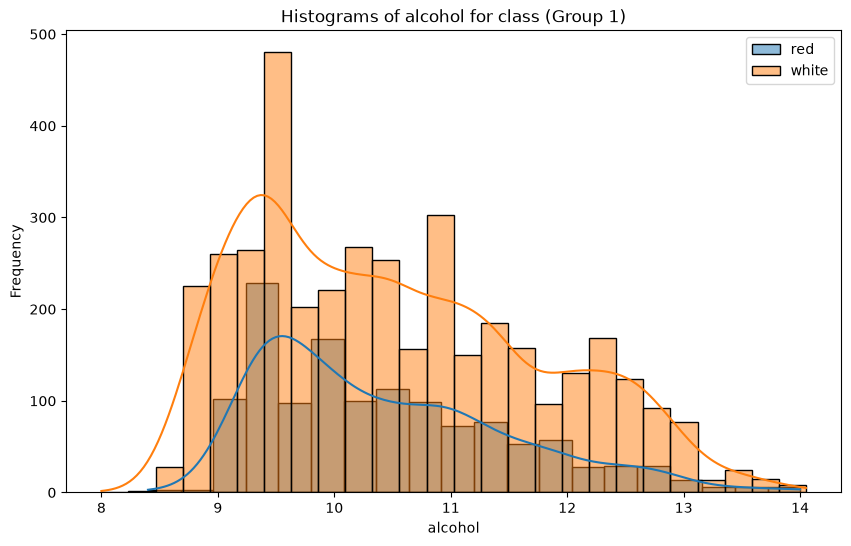

In [16]:
# MiniEDA Regresion

# Categóricas: class y quality

# Quality y alcohol ya la hemos visto antes al estudiar el bivariante del problema de clasificación: es la última gráfica y sí que hay relación.

bt.plot_grouped_histograms(train_set, cat_col= "class", num_col= target_reg, group_size= 2)

*Hay un mínimo de alcohol para el tinto que es mayor que para blanco y algo parecido pasa con la parte alta. Como si el rango de alcohol en los vinos tintos del vinho verde tuvieran un margen más restringido... Me la quedo*

In [17]:
features_cat_reg = ["class","quality"]

In [18]:
# Estudiamos ahora las correlaciones y el mapa de correlaciones

corr = train_set.corr(numeric_only= "True")
np.abs(corr[target_reg]).sort_values(ascending = False)

alcohol                 1.000000
density                 0.682345
quality                 0.450403
residual sugar          0.357459
total sulfur dioxide    0.272970
chlorides               0.260508
free sulfur dioxide     0.188460
pH                      0.116497
fixed acidity           0.091964
volatile acidity        0.036041
citric acid             0.005690
sulphates               0.000412
Name: alcohol, dtype: float64

*Se ha colado quality por sus valores numéricos (ya esta codificada ordinalmente) pero aparte de eso, nos quedamos con las que tengan r > 0.1, aunque podíamos haber sido bastante más exigentes*

In [19]:
r_min = 0.10
features_num_reg_1 = corr[target_reg][(np.abs(corr[target_reg]) > r_min)].index.to_list()
features_num_reg_1.remove("quality")
features_num_reg_2 = [col for col in train_set.columns if col not in features_num_reg_1 and col != target_reg
                       and col not in features_cat_reg]

<Axes: >

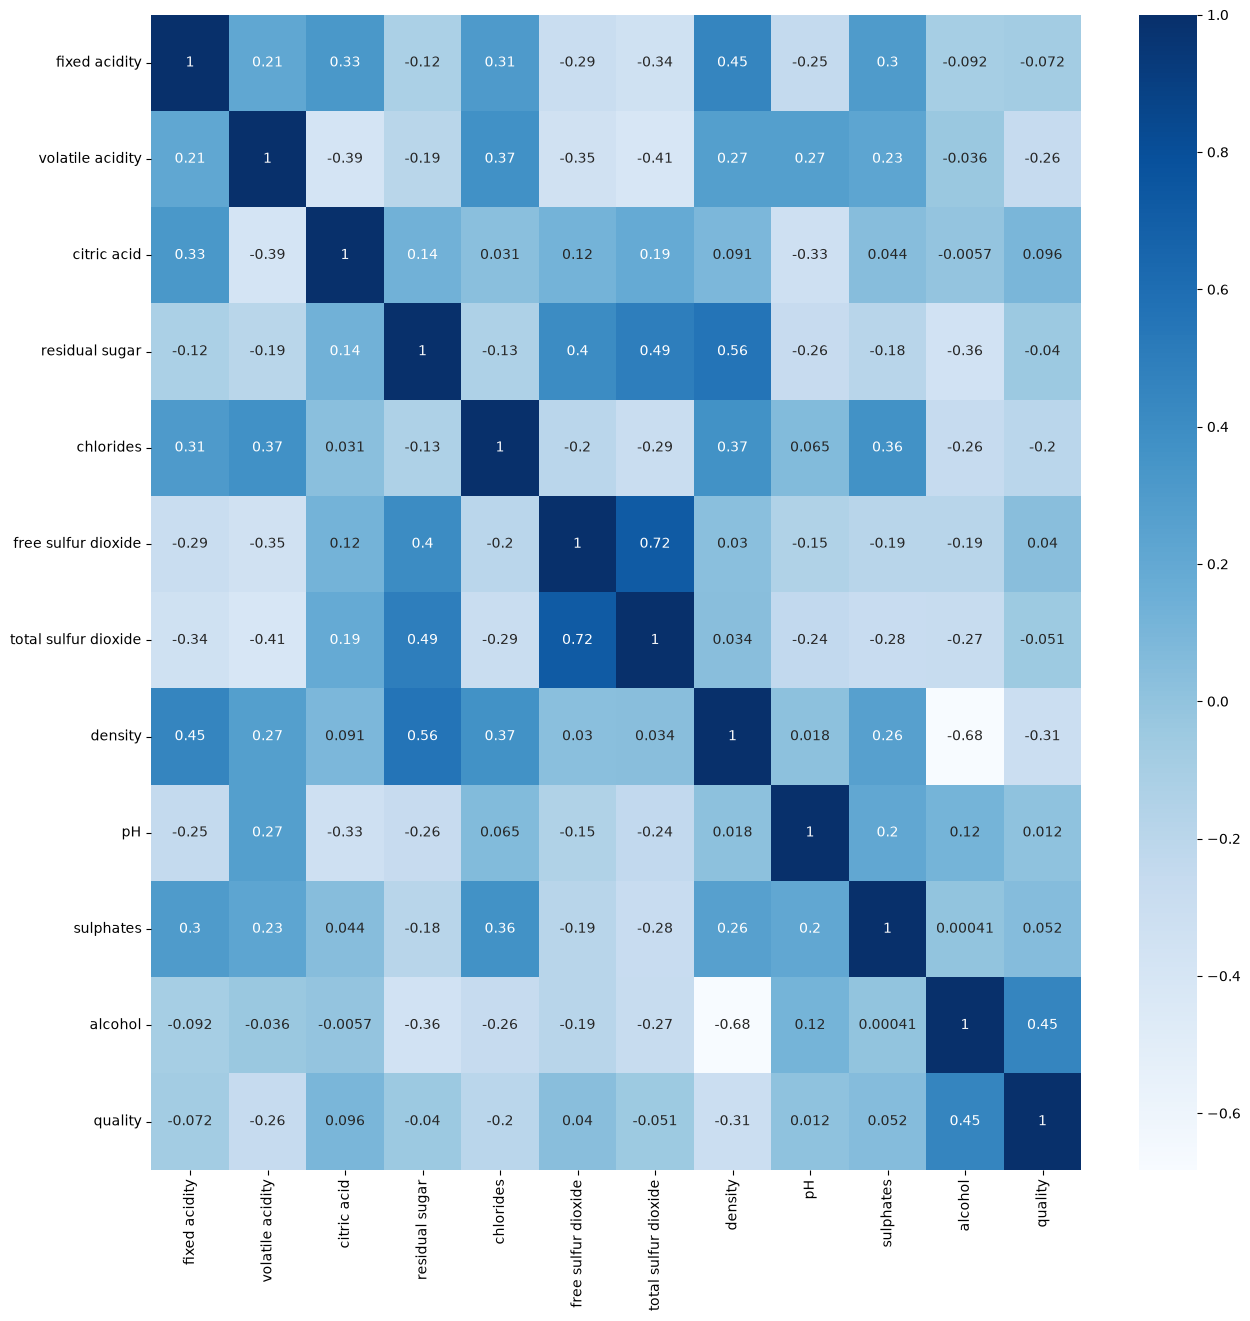

In [20]:
plt.figure(figsize= (15,15))
sns.heatmap(corr, annot= True, cmap = "Blues")

*Aunque hay alguna correlación relativamente significativa entre las features numéricas (residual sugar y density), la que más destaca como era de esperar es la de free sulfur dioxide y total sulfur dioxide. Podemos quedarnos con una y probar a deja la otra fuera*ç


In [21]:
features_num_reg_1.remove("free sulfur dioxide") # Es la que menos correla con alcohol.
features_num_reg_2.append("free sulfur dioxide")

*Tratamos ahora las features (necesitamos escalar porque vamos a emplear un KNN y además tenemos que convertir las categóricas)*

In [22]:
train_set["class"] = (train_set["class"] == "white").astype(int) # white -> clase 1, red -> clase 0
test_set["class"] = (test_set["class"] == "white").astype(int) # white -> clase 1, red -> clase 0

In [23]:
train_set["class"].value_counts()

class
1    3907
0    1290
Name: count, dtype: int64

In [24]:
# Dejamos "quality" y "alcohol" para el final porque son los dos targets, tendremos que procesar en una si y en otra no

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

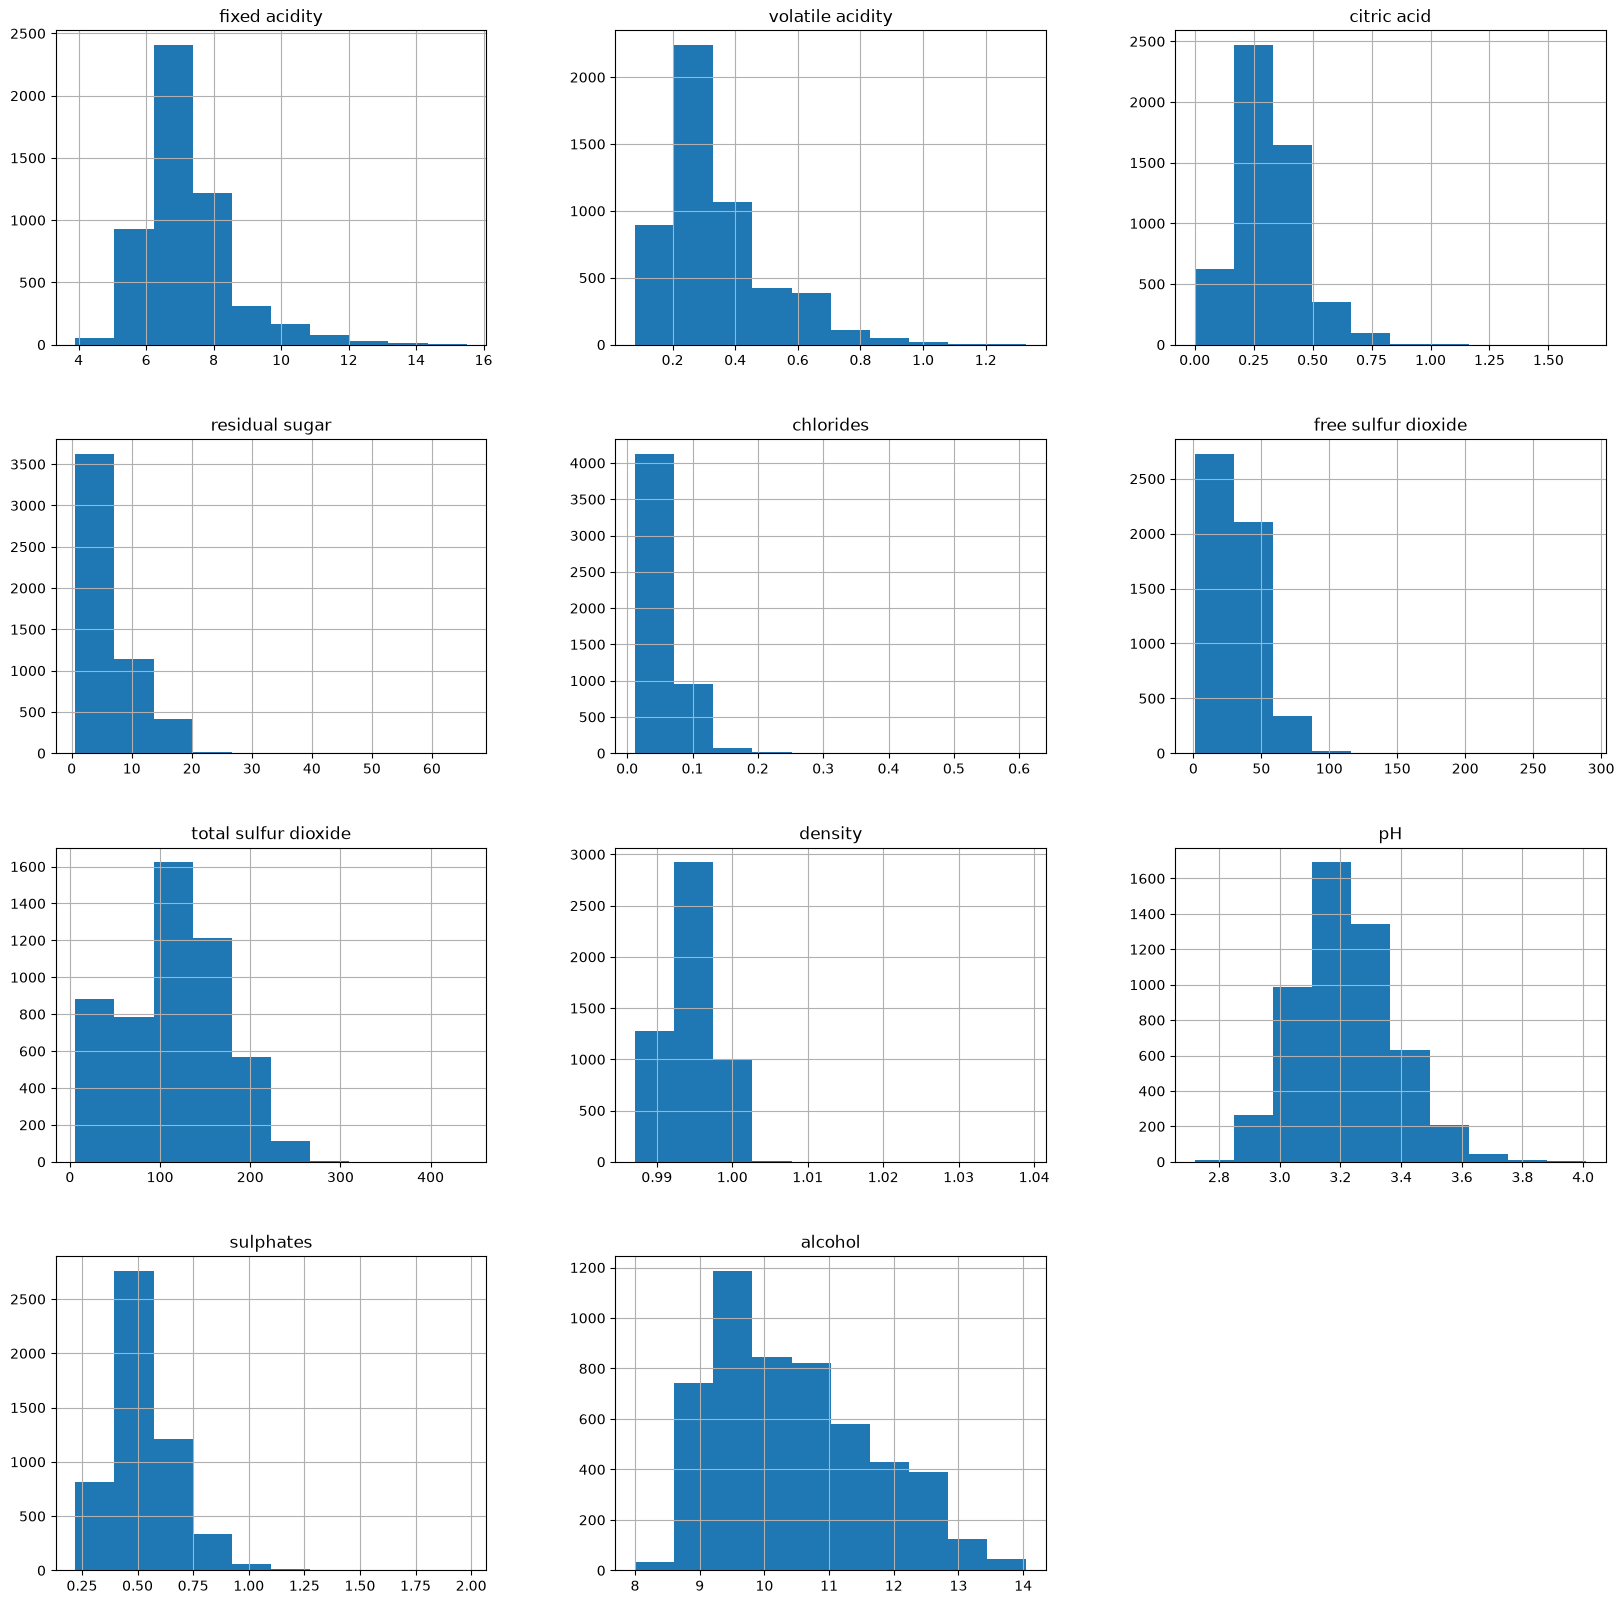

In [25]:
train_set[features_num_clf].hist(figsize = (20,20))
plt.tight_layout

In [26]:
train_set_scaled = train_set.copy()
test_set_scaled = test_set.copy()

In [27]:
features_to_transform = ["residual sugar", "chlorides","free sulfur dioxide", "total sulfur dioxide"]

In [28]:
for col in features_to_transform:
    desplaza = 0 
    if train_set_scaled[col].min() <= 0:
        desplaza = int(abs(train_set_scaled[col].min())) + 1
    train_set_scaled[col] = np.log(train_set_scaled[col] + desplaza)
    test_set_scaled[col] = np.log(test_set_scaled[col] + desplaza)

In [29]:
features_num_clf

['fixed acidity',
 'volatile acidity',
 'citric acid',
 'residual sugar',
 'chlorides',
 'free sulfur dioxide',
 'total sulfur dioxide',
 'density',
 'pH',
 'sulphates',
 'alcohol']

*En features_num_clf están todas las numéricas, así que me ahorra tener que tratarlas por separado, luego sí que las seleccionaremos por separado. Pero ya separando para regresion y para clasificacion*

In [30]:
scaler = StandardScaler()
features_num_reg = features_num_clf.copy()
features_num_reg.remove("alcohol")
train_set_scaled[features_num_reg] = scaler.fit_transform(train_set_scaled[features_num_reg])
test_set_scaled[features_num_reg] = scaler.transform(test_set_scaled[features_num_reg])


*Separamos*

In [31]:
train_set_scaled_clf = train_set_scaled.copy()
test_set_scaled_clf = test_set_scaled.copy()

train_set_scaled_clf["alcohol"] = scaler.fit_transform(train_set_scaled_clf[["alcohol"]])
test_set_scaled_clf["alcohol"] = scaler.transform(test_set_scaled_clf[["alcohol"]])

*No, no nos hemos olvidado de quality pero ya está convertida a ordinal como numérica discreta que es con rango limitad o pequeño de valores*

*Creamos X,y variados*

In [32]:
y_train_clf = train_set[target_clf]
y_test_clf = test_set[target_clf]
y_train_reg = train_set[target_reg]
y_test_reg = test_set[target_reg]


X_train_clf_dict = {}
X_test_clf_dict = {}

X_train_reg_dict = {}
X_test_reg_dict = {}

# Juegos X_train clasificacion

features_set_name = ["cat+num_1",    "todas"]
features_set = [features_cat_clf + featues_num_clf_1,     features_cat_clf + featues_num_clf_1 + features_num_clf_2]

for set_name,feature_list in zip(features_set_name, features_set):
    print(feature_list)
    X_train_clf_dict[set_name] = train_set_scaled_clf[feature_list]
    X_test_clf_dict[set_name] = test_set_scaled_clf[feature_list]

# Juegos X_train regresion
    
features_set_name = ["cat+num_1",    "todas"]
features_set = [features_cat_reg + features_num_reg_1,     features_cat_reg + features_num_reg_1 + features_num_reg_2]

for set_name,feature_list in zip(features_set_name, features_set):
    X_train_reg_dict[set_name] = train_set_scaled[feature_list]
    X_test_reg_dict[set_name] = test_set_scaled[feature_list]

['class', 'volatile acidity', 'citric acid', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
['class', 'volatile acidity', 'citric acid', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'fixed acidity', 'residual sugar']


*Ya lo que queda de sección nos centramos en clasificación*

In [33]:
# Instanciamos modelos
knn_clf = KNeighborsClassifier(n_neighbors= 5)
knn_ten_clf = KNeighborsClassifier(n_neighbors= 10)
lr_clf = LogisticRegression(max_iter = 1000)
rf_clf = RandomForestClassifier(max_depth = 10, random_state= 42)
lgb_clf = LGBMClassifier(max_depth = 10, random_state = 42, verbose = -100)

modelos_clf = {
    "KNN_5": knn_clf,
    "KNN_10": knn_ten_clf,
    "Regresion Logistica": lr_clf,
    "Random Forest": rf_clf,
    "LightGBM": lgb_clf
}

In [34]:
for feature_set, X_train in X_train_clf_dict.items():
    print(f"Para el set {feature_set}:")
    for tipo,modelo in modelos_clf.items():
        print(f"{tipo}: ", end = " ")
        print(np.mean(cross_val_score(modelo, X_train, y_train_clf, cv = 5, scoring = "balanced_accuracy")))
    print("******")

Para el set cat+num_1:
KNN_5:  0.2528105574462743
KNN_10:  0.23998798363139642
Regresion Logistica:  0.22651457029462535
Random Forest:  0.27162486130561775
LightGBM:  0.33280511270119545
******
Para el set todas:
KNN_5:  0.2558732569989652
KNN_10:  0.242474250439742
Regresion Logistica:  0.22709577706699866
Random Forest:  0.2739072236003247
LightGBM:  0.3390454310797876
******


*Los valores son realmente flojos, pero es debido al fuerte desequilibrio que hay entre clases, deberíamos hacer un equilibrado, pero que en nuestro caso se va a centrar por tiempo disponible en usar el parámetro class_weights y el más o menos equivalente de weights en KNN*

In [35]:
# Instanciamos modelos
knn_clf = KNeighborsClassifier(n_neighbors= 5, weights= "distance")
knn_ten_clf = KNeighborsClassifier(n_neighbors= 10, weights = "distance")
lr_clf = LogisticRegression(max_iter = 1000, class_weight = "balanced")
rf_clf = RandomForestClassifier(max_depth = 10, random_state= 42, class_weight = "balanced")
lgb_clf = LGBMClassifier(max_depth = 10, random_state = 42, verbose = -100, class_weight = "balanced")

modelos_clf = {
    "KNN_5": knn_clf,
    "KNN_10": knn_ten_clf,
    "Regresion Logistica": lr_clf,
    "Random Forest": rf_clf,
    "LightGBM": lgb_clf
}

In [36]:
for feature_set, X_train in X_train_clf_dict.items():
    print(f"Para el set {feature_set}:")
    for tipo,modelo in modelos_clf.items():
        print(f"{tipo}: ", end = " ")
        print(np.mean(cross_val_score(modelo, X_train, y_train_clf, cv = 5, scoring = "balanced_accuracy")))
    print("******")

Para el set cat+num_1:
KNN_5:  0.33533206084500317
KNN_10:  0.3335138591815891
Regresion Logistica:  0.3257717722050263
Random Forest:  0.36567533836855565
LightGBM:  0.3565568051511171
******
Para el set todas:
KNN_5:  0.33699063026684994
KNN_10:  0.33802156119799615
Regresion Logistica:  0.3821297490838992
Random Forest:  0.3722704354281799
LightGBM:  0.35964442746981484
******


*Todos los modelos han mejorado, e incluso podríamos quedarnos con la regresión logistica, pero vamos a hacerlo con LightGBM que parece más consistente en todas las pruebas y también permite a titulo ilustrativo más juego en el aspecto de hiperparámetrosÇ*

In [37]:
param_grid = {
    "n_estimators": [100,200,1000],
    "max_depth": [1,5,10,20],
    "learning_rate": [0.1,0.3,0.6,1,0.01]
}



lgb_grid = GridSearchCV(lgb_clf,
                        param_grid= param_grid,
                        cv = 5,
                        scoring = "balanced_accuracy")

lgb_grid.fit(X_train_clf_dict["todas"], y_train_clf)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LGBMClassifie... verbose=-100)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1, 0.3, ...], 'max_depth': [1, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: in

In [38]:
print(lgb_grid.best_params_)
print(lgb_grid.best_score_)

{'learning_rate': 0.01, 'max_depth': 20, 'n_estimators': 200}
0.37134629750829734


In [39]:
print(lgb_grid.get_params())

{'cv': 5, 'error_score': nan, 'estimator__boosting_type': 'gbdt', 'estimator__class_weight': 'balanced', 'estimator__colsample_bytree': 1.0, 'estimator__importance_type': 'split', 'estimator__learning_rate': 0.1, 'estimator__max_depth': 10, 'estimator__min_child_samples': 20, 'estimator__min_child_weight': 0.001, 'estimator__min_split_gain': 0.0, 'estimator__n_estimators': 100, 'estimator__n_jobs': None, 'estimator__num_leaves': 31, 'estimator__objective': None, 'estimator__random_state': 42, 'estimator__reg_alpha': 0.0, 'estimator__reg_lambda': 0.0, 'estimator__subsample': 1.0, 'estimator__subsample_for_bin': 200000, 'estimator__subsample_freq': 0, 'estimator__verbose': -100, 'estimator': LGBMClassifier(class_weight='balanced', max_depth=10, random_state=42,
               verbose=-100), 'n_jobs': None, 'param_grid': {'n_estimators': [100, 200, 1000], 'max_depth': [1, 5, 10, 20], 'learning_rate': [0.1, 0.3, 0.6, 1, 0.01]}, 'pre_dispatch': '2*n_jobs', 'refit': True, 'return_train_score

*Evaluamos contra test y veamos la matriz de confusión para entender los errores*

In [40]:
y_pred = lgb_grid.best_estimator_.predict(X_test_clf_dict["todas"])
print(classification_report(y_test_clf, y_pred))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         6
           4       0.16      0.37      0.23        43
           5       0.62      0.62      0.62       432
           6       0.64      0.39      0.48       562
           7       0.40      0.65      0.50       210
           8       0.34      0.64      0.45        47
           9       0.00      0.00      0.00         0

    accuracy                           0.51      1300
   macro avg       0.31      0.38      0.32      1300
weighted avg       0.57      0.51      0.52      1300



c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


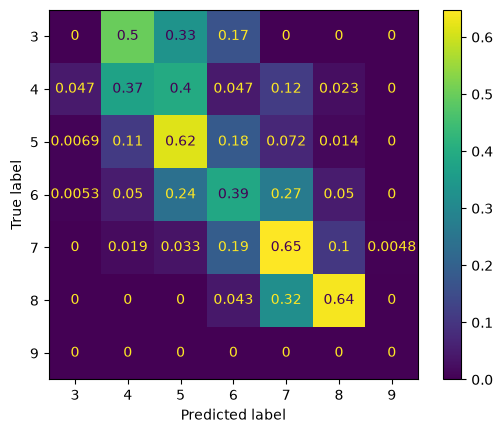

In [41]:
ConfusionMatrixDisplay.from_predictions(y_test_clf, y_pred, normalize = "true")

*Como era de esperar hay bastante poco acierto en general porque hay clases que son tan minoritarias que son idectectables, por ejemplo la calidad 3 es confundida principalmente por un 4 o un 5. La calidad 9 es tan baja que no aparece ni en el test y por tanto tampoco se cuenta, aunque el modeo sí que la otorga (a un real 7 que lo puntúa como 9).*

*Cosas para destacar que pueden ayudarnos a mejorar o plantear alternativas:*
*El recall es realtivamente aceptable en la escala central 5 a 8, salvo curiosamente para el 6, donde hay una fuerte bajada.*  

*Para bien la mayoría de los errores son en puntuaciones uno arriba uno abajo (salvo para el 3), lo cual podemos tenerlo en cuenta quizá para ajustar las probabilidades de corte para que sea más exigente y así hacer que las clases se separen más.*  

*Otras posibles mejoras: Hacer un primer clasificador de más de o igual a 6  puntos frente a menos de 6, y luego intentar clasificar más precisamente en un modelo ensamblado siguiente. O bien podríamos convertirlo en un problema de regresión*  

*Por supuesto conseguir más datos en los que haya calidades más altas y más bajas ayudaría*

### #3 Modelado para regresión

Reutiliza todo lo que puedas la preparación del modelado de la parte anterior y construye ahora el mejor modelo que puedas para predecir el grado alcohólico de un vino dadas sus características fisicoquímicas, su clase y la puntuación de calidad que le ha sido otorgada. Compara al menos tres tipos de modelos, seleccionando una métrica adecuada de comparación y escoge el más apropiado empleando validación cruzada antes o después de optimizar hiperparámetros (en la sesión en vivo lo haremos antes por cuestiones de tiempo). Evalúa el modelo escogido y con los hiperparámetros ajustados de la mejor manera que puedas. Para terminar realizar un pequeño análisis de errores.

*Todo el trabajo está hecho para centrarnos en los modelos y eso vamos a ver empleando además el MAPE como comparativa (porque ninguno tiene 0 como grado alcohólico)*

In [42]:
rf_reg = RandomForestRegressor(max_depth = 10, random_state= 42)
lgb_reg = LGBMRegressor(max_depth = 10, random_state = 42, verbose = -100)
xgb_reg = XGBRegressor(max_depth = 10, random_state = 42)

modelos_reg = {
    "Random Forest": rf_reg,
    "LightGBM": lgb_reg,
    "XGBoost Regressor": xgb_reg
}



In [43]:
for feature_set, X_train in X_train_reg_dict.items():
    print(f"Para el set {feature_set}:")
    for tipo,modelo in modelos_reg.items():
        print(f"{tipo}: ", end = " ")
        print(-np.mean(cross_val_score(modelo, X_train, y_train_reg, cv = 5, scoring = "neg_mean_absolute_percentage_error")))
    print("******")

Para el set cat+num_1:
Random Forest:  4.941384725476132e-05
LightGBM:  0.00027555885224799057
XGBoost Regressor:  4.324891651324625e-05
******
Para el set todas:
Random Forest:  5.52926963416154e-05
LightGBM:  0.0002736360091693899
XGBoost Regressor:  4.949728238969883e-05
******


*En este caso es más interesante usar menos features y nos quedaríamos con el RandomForest por simplicidad frente al XGBoost y métricas similares (los errores son practicamente nulos, lo clava frente al otro problema)*

In [44]:
param_grid = {
    "n_estimators": [100,200,1000],
    "max_depth": [1,5,10,20],
    "max_features": ["log2","sqrt",None]
}

rf_grid = GridSearchCV(rf_reg,
                        param_grid= param_grid,
                        cv = 5,
                        scoring = "neg_mean_absolute_percentage_error")

rf_grid.fit(X_train_reg_dict["todas"], y_train_reg)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [1, 5, ...], 'max_features': ['log2', 'sqrt', ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_absolute_percentage_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True

In [45]:
print(rf_grid.best_params_)
print(rf_grid.best_score_)


{'max_depth': 20, 'max_features': None, 'n_estimators': 1000}
-5.4619378868328366e-05


In [46]:
y_pred = rf_grid.best_estimator_.predict(X_test_reg_dict["todas"])
print("MAPE:", mean_absolute_percentage_error(y_test_reg, y_pred))

MAPE: 0.00011299325506353123


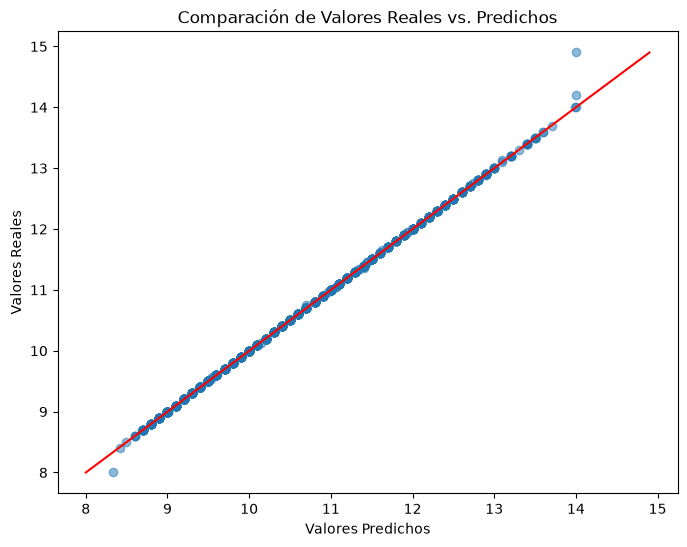

In [47]:
plot_predictions_vs_actual(y_test_reg, y_pred)

*No os acostumbréis, son problemas preparados y así no salen en la vida real nunca :-)*

In [48]:
import pickle
# Save the model to a file
with open('rf_model.pkl', 'wb') as file:
    pickle.dump(rf_grid.best_estimator_, file)
    


In [49]:
# Load the model from the file
with open('rf_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)